# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Федів Андрій'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 13      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 13: Вінниця, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_вінниця


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g

COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    t0, b0 = time.time(), cache_bytes()
    g = clean(getter())
    g.to_parquet(path, index=False)
    g = gpd.read_parquet(path)
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 1)}
    return g


In [7]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 113.1 км²


In [8]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 17989 | ребер 52292


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [9]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.026,0.06
heritage,знімок,159,0.0,0.073,0.027
stations,знімок,4,0.0,0.049,0.024
amenities,знімок,426,0.0,0.097,0.029
мережа walk,знімок,70281,0.0,3.616,0.091


**Висновок до завдання 1.2:**

Другий запуск: усе зі знімка, 0 МБ, ≈0.3 с. Перший, живий, був 277 с і 8.01 МБ, з них 7.73 МБ — мережа. Знімок швидший приблизно у 900 разів.


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [10]:
has_historic = heritage['historic'].notna()
has_tourism  = heritage['tourism'].isin(TOURISM_OK)
mask = has_historic | has_tourism
is_exhibit = heritage['historic'].isin(['aircraft', 'cannon', 'missile'])
mask = mask & ~is_exhibit
has_name = heritage['name'].notna()

cand = heritage[mask & has_name].reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(mask.sum()))
print('з них мають name       :', len(cand))
print('відкинуто безіменних   :', int((mask & ~has_name).sum()))
print('відкинуто експонатів   :', int(is_exhibit.sum()))


усього у шарі heritage : 159
підходять за тегами    : 126
з них мають name       : 105
відкинуто безіменних   : 21
відкинуто експонатів   : 33


In [11]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial          42
building           4
yes                4
manor              2
monument           1
castle             1
boundary_stone     1

=== tourism ===
tourism
artwork       27
museum        13
attraction     8
viewpoint      3

типи геометрії: {'Point': 86, 'Polygon': 17, 'LineString': 2}


**Висновок до завдання 2.1:**

159 обʼєктів. Відкинув 33 експонати музею авіації (літаки, гармати, ракета — це один музей, а не 33 памʼятки) і 21 без назви, бо точку без імені в маршрут не поставиш. Лишилось 105: точки (86) і полігони (17).


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [12]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

cand['wiki'] = (cand['wikidata'].notna() | cand['wikipedia'].notna()).astype(int)
name_cols = [c for c in cand.columns if c.startswith('name:') and c != 'name:uk']
cand['n_lang'] = cand[name_cols].notna().sum(axis=1)
cand['is_museum'] = cand['tourism'].isin(['museum', 'gallery']).astype(int)

cand['n_lang_r'] = cand['n_lang'].rank(pct=True, method='min')

cand['score'] = 0.5 * cand['wiki'] + 0.35 * cand['n_lang_r'] + 0.15 * cand['is_museum']

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('мають переклад назви:', int((cand['n_lang'] > 0).sum()), '\nмузеїв:', int(cand['is_museum'].sum()))


кандидатів   : 105
мають wiki   : 22
мають переклад назви: 27 
музеїв: 13


**Висновок до завдання 3.1:**

Три сигнали: wiki 0.5, переклади назви 0.35, музей 0.15. Вікіпедія найважча, бо це визнання ззовні OSM; переклади важать більше за музей, бо їх теж роблять для чужих, а не для карти. Мають wiki 22 зі 105, переклад 27, музеїв 13.


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [13]:
N_SMALL, N_LARGE = 10, 30

top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)
overlap   = len(set(top10['name']) & set(top_naive['name']))
print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за моїм критерієм': list(top10['name']),
                      'за площею': list(top_naive['name'])}))


перетин: 4 з 10


,за моїм критерієм,за площею
0,Обласний краєзнавчий музей,Музей Повітряних Сил
1,Музей моделей транспорту,Національний музей-садиба М. І. Пирогова
2,Національний музей-садиба М. І. Пирогова,"Фонтан ""Рошен"""
3,Обласний художній музей,Спасо-Преображенський кафедральний собор
4,Музей М. М. Коцюбинського,Садиба Львовича
5,Синагога Ліфшиця,Дача Майка
6,Спасо-Преображенський кафедральний собор,Пам'ятник загиблим 14 липня 2022
7,"Фонтан ""Рошен""",Синагога Ліфшиця
8,Василеві Стусу,Маєток Болеслава Лещинського
9,Палац Грохольських,Будинок Натана Альтмана


**Висновок до завдання 3.2:**

Збіглося 4 з 10. За площею в десятку потрапили садиби й дачі без статей у Вікіпедії, а Музей Повітряних Сил там перший. Той самий код і дані, а 6 позицій з 10 інші, тож «найкращі» задає критерій.


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [14]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

pairs = close_pairs(top_score)
print('пар ближче 60 м у топ-%d: %d' % (len(top_score), len(pairs)))
for i, j, d in pairs:
    print('  %3.0f м  [%2d] %s  -  [%2d] %s' % (d, i, top_score['name'].iloc[i], j, top_score['name'].iloc[j]))

dup = [j for i, j, d in pairs if top_score['name'].iloc[i] == top_score['name'].iloc[j]]
if dup:
    ranked = cand.nlargest(N_LARGE + len(dup), 'score').reset_index(drop=True)
    top_score = ranked.drop(index=dup).head(N_LARGE).reset_index(drop=True)
    top10 = top_score.head(N_SMALL)
print('злито дублікатів: %d | лишилось близьких пар: %d' % (len(dup), len(close_pairs(top_score))))


пар ближче 60 м у топ-30: 7
   35 м  [ 3] Обласний художній музей  -  [14] Тарасові Шевченку
   37 м  [ 3] Обласний художній музей  -  [ 6] Спасо-Преображенський кафедральний собор
   39 м  [ 1] Музей моделей транспорту  -  [ 5] Синагога Ліфшиця
   41 м  [ 0] Обласний краєзнавчий музей  -  [14] Тарасові Шевченку
   49 м  [ 0] Обласний краєзнавчий музей  -  [ 3] Обласний художній музей
   51 м  [ 1] Музей моделей транспорту  -  [27] Юзефу Пілсудському.
   53 м  [ 5] Синагога Ліфшиця  -  [27] Юзефу Пілсудському.
злито дублікатів: 0 | лишилось близьких пар: 7


**Висновок до завдання 3.3:**

7 пар ближче 60 м, дублікатів за назвою нема: це сусідні музеї, собор і памʼятники. Лишив усі.


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [15]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 4
                 name  railway       building
0                5 км     halt            NaN
1             Вінниця  station            NaN
2    Вінниця-Вантажна     halt            NaN
3  Залізничний вокзал      NaN  train_station


In [16]:
city_name = CITY.split(',')[0]
station = stations[(stations['railway'] == 'station').fillna(False)
                   & (stations['name'] == city_name).fillna(False)]
assert len(station) == 1, 'очікував рівно один головний вокзал, знайдено %d' % len(station)
print('старт:', station['name'].iloc[0], '| геометрія:', station.geometry.geom_type.iloc[0])


старт: Вінниця | геометрія: Point


In [17]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 17989 вузлів, 51772 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [18]:
def check_snap(points, ids, dist, label):
    n_pts, n_nodes = len(ids), len(set(ids))
    worst = int(np.argmax(dist))
    print('%s: точок %d, різних вузлів %d' % (label, n_pts, n_nodes))
    print('   відстань точка→вузол: медіана %.0f м, максимум %.0f м («%s»)'
          % (np.median(dist), dist[worst], points['name'].iloc[worst]))
    if n_nodes < n_pts:
        groups = collections.defaultdict(list)
        for name, nid in zip(points['name'], ids):
            groups[nid].append(name)
        for nid, names in groups.items():
            if len(names) > 1:
                print('   ЗЛИПЛИСЬ на вузлі %s: %s' % (nid, ' | '.join(names)))
        print('   такі пари отримають віддаль 0 м у матриці')
    else:
        print('   усі точки на різних вузлах — добре')


---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [19]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    p = points.to_crs(32635).geometry
    XY = np.c_[p.x.values, p.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    m = np.isfinite(D) & (E > 0)
    np.fill_diagonal(m, False)
    return float(np.median(D[m] / E[m]))


**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [20]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

мала задача: точок 11, різних вузлів 10
   відстань точка→вузол: медіана 22 м, максимум 64 м («Обласний краєзнавчий музей»)
   ЗЛИПЛИСЬ на вузлі 9909099954: Обласний краєзнавчий музей | Обласний художній музей
   такі пари отримають віддаль 0 м у матриці


матриця за 0.305 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.19


**Висновок до завдань 4.1 і 5.1:**

11 точок сіли на 10 вузлів: краєзнавчий і художній музеї в одному комплексі, між ними 0 м — зафіксував, не правив. Медіана привʼязки 22 м, максимум 64 м. Обхід 1.19, асиметрія 0, бо мережа пішохідна.


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [21]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    k = len(D)
    visited = [False] * k
    tour, cur = [0], 0
    visited[0] = True
    for _ in range(k - 1):
        best = min((j for j in range(k) if not visited[j]), key=lambda j: D[cur, j])
        tour.append(best); visited[best] = True; cur = best
    tour.append(0)
    return tour

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    tour = list(tour)
    k = len(tour)
    improved = True
    while improved:
        improved = False
        for i in range(1, k - 2):
            for j in range(i + 1, k - 1):
                a, b, c, d = tour[i - 1], tour[i], tour[j], tour[j + 1]
                old = D[a, b] + D[c, d]
                new = D[a, c] + D[b, d]
                if new < old - 1e-9:
                    tour[i:j + 1] = tour[i:j + 1][::-1]
                    improved = True
    return tour


In [22]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [23]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [24]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,23717,5.82
2-opt,22412,0.00
Held-Karp (точний),22412,0.00



оптимальний порядок:
   0. СТАРТ: Вінниця
   1. Фонтан "Рошен"
   2. Обласний художній музей
   3. Обласний краєзнавчий музей
   4. Спасо-Преображенський кафедральний собор
   5. Музей моделей транспорту
   6. Синагога Ліфшиця
   7. Василеві Стусу
   8. Національний музей-садиба М. І. Пирогова
   9. Палац Грохольських
  10. Музей М. М. Коцюбинського
  11. СТАРТ: Вінниця

довжина: 22.41 км


**Висновок до завдання 6.1:**

Найближчий сусід 23 717 м, гірший за оптимум 22 412 м на 5.8 %. 2-opt дійшов до оптимуму. Очікував 20–30 %, але точки лежать майже на одній лінії вокзал — центр — садиба Пирогова, тому жадібний майже не помиляється.


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [25]:
rows = []
for n in [11, 16, 21, 26, 31]:
    N = n - 1
    cells = 2 ** N * N
    rows.append({'точок n': n, 'клітин 2^(n−1)·(n−1)': cells,
                 'памʼять, ГБ (8 байт/клітина)': cells * 8 / 1e9})
with pd.option_context('display.float_format', lambda v: '%.3g' % v):
    display(pd.DataFrame(rows).set_index('точок n'))
print('оперативна памʼять цього компʼютера: %.0f ГБ' % (os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 1e9))


,клітин 2^(n−1)·(n−1),"памʼять, ГБ (8 байт/клітина)"
точок n,,
11,10240,8.19e-05
16,491520,0.00393
21,20971520,0.168
26,838860800,6.71
31,32212254720,258


оперативна памʼять цього компʼютера: 16 ГБ


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

**Висновок до завдання 6.2:**

Останній рядок: n = 31 дає 2³⁰·30 = 3.2·10¹⁰ клітин, це 258 ГБ при 8 байтах на клітину, а в компʼютері 16 ГБ. Таблицю dp неможливо навіть створити: `held_karp` упаде з MemoryError ще до першої ітерації, тож справа не в тому, що «довго», а в тому, що немає памʼяті. Кожні +5 точок множать таблицю у 38 разів (n = 26 це ще 6.7 ГБ, n = 31 уже 258).


In [26]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

велика задача: точок 31, різних вузлів 29
   відстань точка→вузол: медіана 22 м, максимум 93 м («Пам'ятник першому трамваю»)
   ЗЛИПЛИСЬ на вузлі 9909099954: Обласний краєзнавчий музей | Обласний художній музей | Тарасові Шевченку
   такі пари отримають віддаль 0 м у матриці


коефіцієнт обходу: 1.18
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    45584 м
2-opt            :    36458 м  за 0.001 с  (коротше на 20.0%)

ЦЕ — база порівняння для лабораторної роботи № 8.


**Висновок до великої задачі:**

29 вузлів на 31 точку: на тому ж вузлі ще й памʼятник Шевченку. Обхід 1.18. NN 45 584 м, 2-opt 36 458 м за тисячні частки секунди, на 20 % коротше. Це база для ЛР8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м
кандидатів: 105 | зайнятих комірок: 64 | половина кандидатів у 16 найщільніших комірках (найбільша: 8)


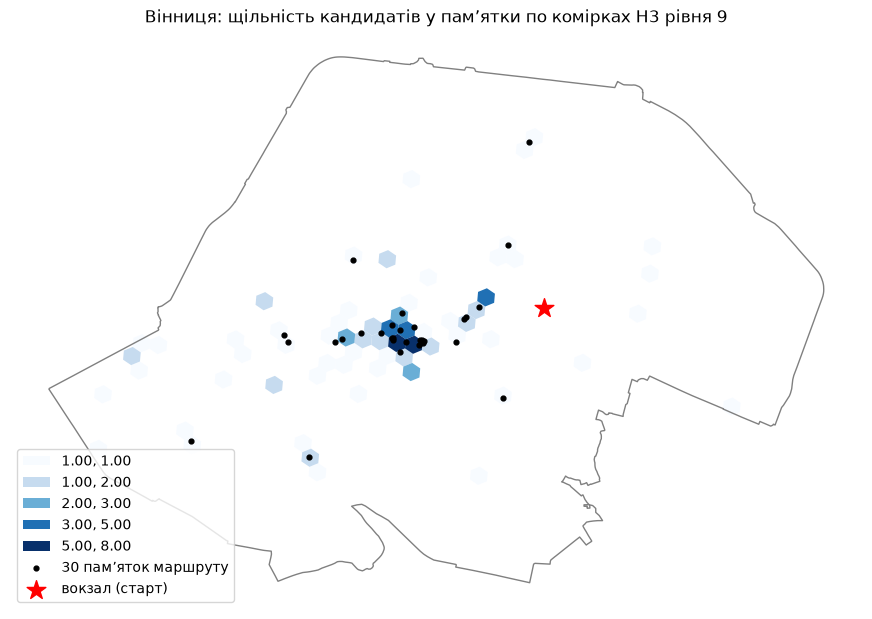

In [27]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print("середнє ребро комірки: %.0f м" % h3.average_hexagon_edge_length(H3_RES, unit="m"))

rep = cand.geometry.representative_point()
cand["h3"] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in rep]
dens = cand["h3"].value_counts().rename_axis("h3").reset_index(name="n")

hexes = gpd.GeoDataFrame(
    dens, geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in dens["h3"]], crs="EPSG:4326"
)

half_cells = int((dens["n"].cumsum() < len(cand) / 2).sum() + 1)
print(
    "кандидатів: %d | зайнятих комірок: %d | половина кандидатів у %d найщільніших комірках (найбільша: %d)"
    % (len(cand), len(dens), half_cells, dens["n"].max())
)

fig, ax = plt.subplots(figsize=(11, 9))
boundary.boundary.plot(ax=ax, color="gray", linewidth=1)
hexes.plot(
    ax=ax,
    column="n",
    cmap="Blues",
    scheme="NaturalBreaks",
    k=5,
    legend=True,
    legend_kwds={"title": "кандидатів у комірці", "loc": "lower right"},
)
pts30.iloc[1:].plot(ax=ax, color="black", markersize=12, label="30 памʼяток маршруту")
pts30.iloc[[0]].plot(ax=ax, color="red", marker="*", markersize=200, label="вокзал (старт)")
ax.set_title("%s: щільність кандидатів у памʼятки по комірках H3 рівня 9" % city_name)
ax.legend(loc="lower left")
ax.set_axis_off()
plt.show()


**Висновок до завдання 7.1:**

Ребро 201 м. 105 кандидатів у 64 комірках, половина у 16, найбільша 8. Без експонатів музею авіації центр рівномірний. Маршрут зіркоподібний: клубок у центрі і промені до садиби Пирогова та музею авіації.


> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [28]:
am = (amenities[['name', 'amenity', 'geometry']]
      .rename(columns={'name': 'заклад', 'amenity': 'тип'})
      .to_crs(32635))
pm = pts30[['name', 'geometry']].rename(columns={'name': 'точка маршруту'}).to_crs(32635)

near = gpd.sjoin_nearest(pm, am, how='left', distance_col='відстань, м')
near = near.loc[~near.index.duplicated()]
near['відстань, м'] = near['відстань, м'].round(0).astype(int)
display(near[['точка маршруту', 'заклад', 'тип', 'відстань, м']])


,точка маршруту,заклад,тип,"відстань, м"
0,СТАРТ: Вінниця,NaN,toilets,112
1,Обласний краєзнавчий музей,NaN,drinking_water,76
2,Музей моделей транспорту,Fluid,cafe,37
3,Національний музей-садиба М. І. Пирогова,NaN,toilets,134
4,Обласний художній музей,NaN,drinking_water,27
5,Музей М. М. Коцюбинського,Аристократ,restaurant,24
6,Синагога Ліфшиця,Fluid,cafe,71
7,Спасо-Преображенський кафедральний собор,NaN,drinking_water,24
8,"Фонтан ""Рошен""",NaN,toilets,118
9,Василеві Стусу,Плеяда,cafe,131


**Висновок до завдання 8.1:**

Медіана до найближчого закладу 96 м, максимум 624 м (Алея писанок). Обидва шари в метрах через to_crs(32635).


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [29]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

road = route_coords(ex10, ids10)
straight = [(float(pts10.geometry.y.iloc[i]), float(pts10.geometry.x.iloc[i])) for i in ex10]

fmap = folium.Map(location=straight[0], zoom_start=13, tiles=BASEMAP)
folium.PolyLine(road, color='#2a78d6', weight=4, tooltip='маршрут по вулицях (ребра графа)').add_to(fmap)
folium.PolyLine(straight, color='#eb6834', weight=2, dash_array='6 8', tooltip='прямі відрізки між точками').add_to(fmap)
for step, i in enumerate(ex10[:-1]):
    html = ('<div style="width:22px;height:22px;border-radius:50%%;background:white;border:2px solid #2a78d6;'
            'font:bold 11px sans-serif;text-align:center;line-height:18px">%d</div>' % step)
    folium.Marker(straight[step], tooltip='%d. %s' % (step, pts10['name'].iloc[i]),
                  icon=folium.DivIcon(html=html, icon_size=(22, 22), icon_anchor=(11, 11))).add_to(fmap)
fmap.save('lr5_маршрут.html')
print('збережено lr5_маршрут.html')
print('по вулицях %.2f км, по прямій %.2f км' % (L_opt / 1000, tour_length(E10, ex10) / 1000))
fmap


збережено lr5_маршрут.html
по вулицях 22.41 км, по прямій 17.84 км


**Висновок до завдання 9.1:**

По вулицях 22.41 км, по прямій 17.84 км, різниця 20 %. Суцільна лінія огинає квартали, пунктир іде навпростець.


---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [30]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (15.7 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [ ]:
REPORT = """
1. Відкинув 54 обʼєкти зі 159: 33 експонати музею авіації (один музей, а не 33 памʼятки)
   і 21 без name, бо точку без імені в маршрут не поставиш. Замовнику без пояснень не віддав
   би: білий список tourism, виключення експонатів і відкидання безіменних — мої рішення.
2. wiki 0.5, переклади назви без name:uk 0.35, музей 0.15. Стаття у Вікіпедії — найсильніше
   зовнішнє визнання, тому половина; переклади важать більше за музей, бо їх теж роблять для
   чужих. Площу не брав: великим буває і склад.
3. 4 з 10. Ті самі дані і код, а 6 позицій з 10 інші: «найкращі» — властивість критерію,
   а не даних.
4. 1.19 (мала) і 1.18 (велика) — біля нижньої межі типових 1.2–1.6: центр — прямокутна сітка,
   а далекі точки звʼязані магістралями майже по прямій. Асиметрія 0, бо мережа пішохідна.
5. На 5.82 % (23 717 проти 22 412 м). Здивувало, що так мало: точки лежать майже на одній
   лінії вокзал — центр — садиба Пирогова. 2-opt дав рівно оптимум.
6. Таблиця Held–Karp 2^30·30 = 3.2·10^10 клітин = 258 ГБ при 8 байтах на клітину, а памʼяті
   16 ГБ. Бракує памʼяті, а не часу.
7. 33 літаки й гармати музею авіації занесені окремими обʼєктами — без виключення одна
   комірка H3 мала б 34 «памʼятки»; 21 обʼєкт без назви; два музеї і памʼятник на одному вузлі графа — між ними 0 м, лишив
   і зафіксував; «Памʼятник першому трамваю» з тегом museum; назва «Юзефу Пілсудському.»
   з крапкою;

Декларація про використання ШІ: Декларація про використання ШІ: код частково писав із GPT. 
Те, що він писав перевіряв та підправляв: п.8-9, 
допомагав ШІ із тлумачнням висновків
"""
print(REPORT)


1. Відкинув 54 обʼєкти зі 159: 33 експонати музею авіації (один музей, а не 33 памʼятки)
   і 21 без name, бо точку без імені в маршрут не поставиш. Замовнику без пояснень не віддав
   би: білий список tourism, виключення експонатів і відкидання безіменних — мої рішення.
2. wiki 0.5, переклади назви без name:uk 0.35, музей 0.15. Стаття у Вікіпедії — найсильніше
   зовнішнє визнання, тому половина; переклади важать більше за музей, бо їх теж роблять для
   чужих. Площу не брав: великим буває і склад.
3. 4 з 10. Ті самі дані і код, а 6 позицій з 10 інші: «найкращі» — властивість критерію,
   а не даних.
4. 1.19 (мала) і 1.18 (велика) — біля нижньої межі типових 1.2–1.6: центр — прямокутна сітка,
   а далекі точки звʼязані магістралями майже по прямій. Асиметрія 0, бо мережа пішохідна.
5. На 5.82 % (23 717 проти 22 412 м). Здивувало, що так мало: точки лежать майже на одній
   лінії вокзал — центр — садиба Пирогова. 2-opt дав рівно оптимум.
6. Таблиця Held–Karp 2^30·30 = 3.2·10^10 клітин